# Tumor vs non-tumor cell-type deconvolution barplot — all_batches (HCG-based)

Same figure as `Combined_sample2/final_python.ipynb` (cell 114). Reads `output.csv`
(the UXM deconvolution output produced by `code/deconv_run.sh`) and plots the per-cell-type
fraction difference **non-tumor − tumor**. Purple = enriched in non-tumor, green = enriched
in tumor. Tumor = HCG tumor1+tumor2, non-tumor = monocyte.

Run `sbatch code/deconv_run.sh` first (from the snakemake dir) so `output.csv` exists here.

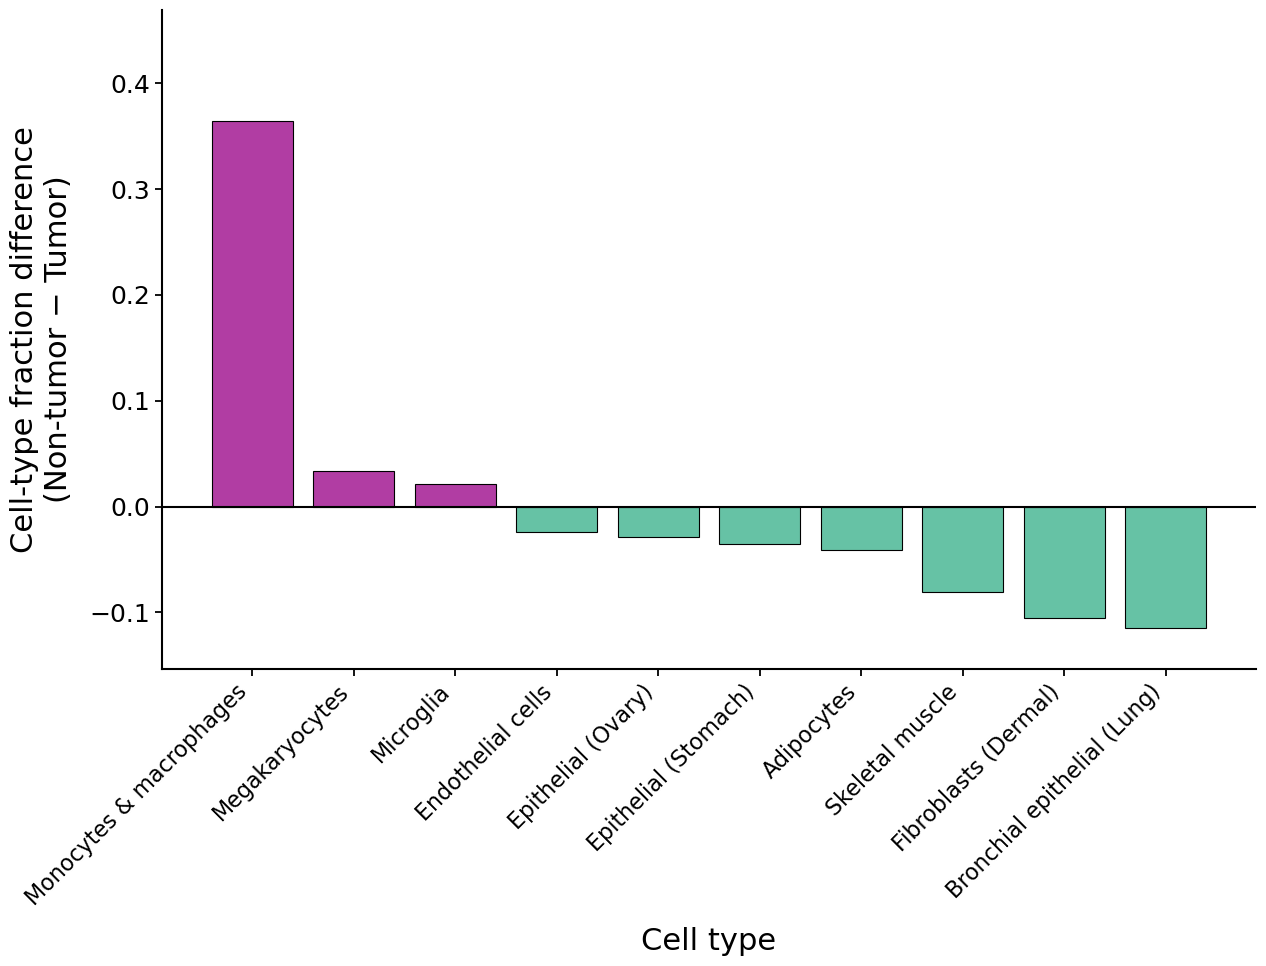

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Make fonts editable in Illustrator/Adobe
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# Publication-level global styling
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 22,
    "axes.titlesize": 24,
    "xtick.labelsize": 16,
    "ytick.labelsize": 18,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.3,
    "ytick.major.width": 1.3,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
})

# output.csv columns: CellType, combined_sorted_tumor, combined_sorted_nontumor
df = pd.read_csv("/home/jmj7858/epifluidlab/meningioma_scnomehic/snakemake/subset_clustering/250kb/all_batches/deconv/output.csv")

# Official display names for the UXM / Loyfer-atlas short labels.
# Applied to the plot only - output.csv keeps the raw atlas names.
CELLTYPE_LABELS = {
    # blood / immune
    "Blood-B":           "B cells",
    "Blood-T":           "T cells",
    "Blood-NK":          "NK cells",
    "Blood-Granul":      "Granulocytes",
    "Blood-Mono+Macro":  "Monocytes & macrophages",
    "Eryth-prog":        "Erythrocyte progenitors",
    "Megakaryocytes":    "Megakaryocytes",
    "Microglia":         "Microglia",
    # brain
    "Astrocyte":         "Astrocytes",
    "Neuron":            "Neurons",
    "Oligodend":         "Oligodendrocytes",
    # epithelial
    "Bladder-Ep":        "Epithelial (Bladder)",
    "Colon-Ep":          "Epithelial (Colon)",
    "Fallopian-Ep":      "Epithelial (Fallopian tube)",
    "Gallbladder":       "Epithelial (Gallbladder)",
    "Gastric-Ep":        "Epithelial (Stomach)",
    "Head-Neck-Ep":      "Epithelial (Head & neck)",
    "Kidney-Ep":         "Epithelial (Kidney)",
    "Ovary-Ep":          "Epithelial (Ovary)",
    "Prostate-Ep":       "Epithelial (Prostate)",
    "Small-Int-Ep":      "Epithelial (Small intestine)",
    "Thyroid-Ep":        "Epithelial (Thyroid)",
    "Breast-Basal-Ep":   "Basal epithelial (Breast)",
    "Breast-Luminal-Ep": "Luminal epithelial (Breast)",
    "Lung-Ep-Alveo":     "Alveolar epithelial (Lung)",
    "Lung-Ep-Bron":      "Bronchial epithelial (Lung)",
    "Epid-Kerat":        "Keratinocytes (Epidermis)",
    # stroma / vasculature
    "Endothel":          "Endothelial cells",
    "Colon-Fibro":       "Fibroblasts (Colon)",
    "Dermal-Fibro":      "Fibroblasts (Dermal)",
    "Heart-Fibro":       "Fibroblasts (Heart)",
    "Adipocytes":        "Adipocytes",
    "Bone-Osteob":       "Osteoblasts",
    # muscle
    "Heart-Cardio":      "Cardiomyocytes",
    "Skeletal-Musc":     "Skeletal muscle",
    "Smooth-Musc":       "Smooth muscle",
    # liver / pancreas
    "Liver-Hep":         "Hepatocytes",
    "Pancreas-Acinar":   "Acinar cells (Pancreas)",
    "Pancreas-Alpha":    "Alpha cells (Pancreas)",
    "Pancreas-Beta":     "Beta cells (Pancreas)",
    "Pancreas-Delta":    "Delta cells (Pancreas)",
    "Pancreas-Duct":     "Duct cells (Pancreas)",
}
_unmapped = sorted(set(df["CellType"]) - set(CELLTYPE_LABELS))
if _unmapped:
    print("WARNING - no official name for:", _unmapped)
df["CellType"] = df["CellType"].map(lambda x: CELLTYPE_LABELS.get(x, x))

df["difference"] = df["combined_sorted_nontumor"] - df["combined_sorted_tumor"]
df = df[(df["combined_sorted_nontumor"] != 0) | (df["combined_sorted_tumor"] != 0)]
df = df[abs(df["difference"]) > 0.01]
df = df.sort_values("difference", ascending=False)

tumor_color    = "#66C2A5"   # enriched in tumor
monocyte_color = "#B13DA3"   # enriched in non-tumor

colors = [monocyte_color if x > 0 else tumor_color for x in df["difference"]]

fig, ax = plt.subplots(figsize=(13, 10))

ax.bar(
    df["CellType"],
    df["difference"],
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

ax.axhline(0, color="black", linewidth=1.5)

# headroom: pad the y-limits so the tallest bar and the y-label are not cut off
_lo, _hi = df["difference"].min(), df["difference"].max()
_rng = _hi - _lo
ax.set_ylim(_lo - 0.08 * _rng, _hi + 0.22 * _rng)

ax.set_ylabel(
    "Cell-type fraction difference\n(Non-tumor − Tumor)",
    fontsize=22,
    labelpad=12
)

ax.set_xlabel(
    "Cell type",
    fontsize=22,
    labelpad=12
)

ax.tick_params(axis="x", labelsize=16, rotation=45)
ax.tick_params(axis="y", labelsize=18)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

plt.tight_layout()

plt.savefig("/home/jmj7858/epifluidlab/meningioma_scnomehic/snakemake/subset_clustering/250kb/all_batches/deconv/celltype_difference_barplot.pdf", bbox_inches="tight")
plt.savefig("/home/jmj7858/epifluidlab/meningioma_scnomehic/snakemake/subset_clustering/250kb/all_batches/deconv/celltype_difference_barplot.png", dpi=600, bbox_inches="tight")

plt.show()